In [1]:
import pandas as pd

In [2]:
womens_df = pd.read_csv("Womens Clothing E-Commerce Reviews.csv")

In [3]:
womens_df.shape

(23486, 11)

In [4]:
womens_df.head()

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [5]:
womens_reviews_df = womens_df[['Title','Review Text','Rating'  ]]

In [6]:
womens_reviews_df.head()

,Title,Review Text,Rating
0,NaN,Absolutely wonderful - silky and sexy and comf...,4
1,NaN,Love this dress! it's sooo pretty. i happene...,5
2,Some major design flaws,I had such high hopes for this dress and reall...,3
3,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5
4,Flattering shirt,This shirt is very flattering to all due to th...,5


In [7]:
womens_reviews_df['Sentiment'] = womens_reviews_df['Rating'].map(lambda r: "poor" if r <= 2 else ("neutral" if r == 3 else "good"))


/var/folders/mq/bp9wv7ld1bscd9fvvns2ftkh0000gn/T/ipykernel_6563/3017439987.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  womens_reviews_df['Sentiment'] = womens_reviews_df['Rating'].map(lambda r: "poor" if r <= 2 else ("neutral" if r == 3 else "good"))


In [8]:
womens_reviews_df.head()

,Title,Review Text,Rating,Sentiment
0,NaN,Absolutely wonderful - silky and sexy and comf...,4,good
1,NaN,Love this dress! it's sooo pretty. i happene...,5,good
2,Some major design flaws,I had such high hopes for this dress and reall...,3,neutral
3,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,good
4,Flattering shirt,This shirt is very flattering to all due to th...,5,good


In [9]:
womens_reviews_df.tail()

,Title,Review Text,Rating,Sentiment
23481,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,good
23482,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,neutral
23483,"Cute, but see through","This fit well, but the top was very see throug...",3,neutral
23484,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,neutral
23485,Please make more like this one!,This dress in a lovely platinum is feminine an...,5,good


In [10]:
womens_reviews_df['Sentiment'].value_counts()

Sentiment
good       18208
neutral     2871
poor        2407
Name: count, dtype: int64

In [11]:
avg_word_count = womens_reviews_df['Review Text'].dropna().str.split().str.len().mean()
print(f"Average review length: {avg_word_count:.2f} words")


Average review length: 60.20 words


In [12]:
avg_length = womens_reviews_df['Review Text'].dropna().str.len().mean()
print(f"Average review length: {avg_length:.2f} characters")


Average review length: 308.69 characters


In [13]:
total_word_count = womens_reviews_df['Review Text'].dropna().str.split().str.len().sum()
print(f"Total word count in review field: {total_word_count:.2f} words")

Total word count in review field: 1362913.00 words


In [14]:
from dotenv import load_dotenv
load_dotenv('/Users/adityanarvekar/agentic/agents/.env')

True

In [15]:
from pydantic import BaseModel, Field, field_validator, ValidationError

class InputState(BaseModel):
    review_text: str = Field(description="The text of the review to analyze.")

    @field_validator('review_text')
    def validate_review_text(cls, value):
        if not value or not isinstance(value, str):
            raise ValidationError("Review text must be a non-empty string.")
        return value

class OutputState(BaseModel):
    sentiment: str = Field(description="The sentiment of the review.")
    reasoning: str = Field(description="The reasoning for the sentiment analysis.")

class ReviewState(BaseModel):
    agreement: bool = Field(description="Whether the reviewer agrees with the sentiment based on the reasoning.")
    review_reasoning: str = Field(description="The reasoning provided by the reviewer for their agreement or disagreement.")
    @field_validator('agreement')
    def validate_agreement(cls, value):
        if not isinstance(value, bool):
            raise ValidationError("Agreement must be a boolean value.")
        return value
    
class OverallState(BaseModel):
    review_text: str = Field(description="The text of the review to analyze.")
    sentiment: str = Field(default="", description="The sentiment of the review.")
    reasoning: str = Field(default="", description="The reasoning for the sentiment analysis.")
    agreement: bool = Field(default=False, description="Whether the reviewer agrees with the sentiment based on the reasoning.")
    review_reasoning: str = Field(default="", description="The reasoning provided by the reviewer for their agreement or disagreement.")
    review_count: int = Field(default=0, description="The number of reviews processed so far.")
    

In [16]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)



In [17]:
llm_answer = llm.with_structured_output(OutputState)

In [18]:
def generate_answer(state: OverallState):
    if state.review_count == 0:
        print("Processing first review. Generating sentiment analysis.")
        prompt = f"""
        Analyze the following review and determine its sentiment (good, neutral, or poor). Provide reasoning for your analysis.

        Review: "{state.review_text}"
        """
        response = llm_answer.invoke(prompt)
        
        sentiment = response.sentiment
        reasoning = response.reasoning
    else:
        print(f"Processing review #{state.review_count + 1}. Generating sentiment analysis based on previous reviewer's feedback.")
        prompt = f"""
        Analyze the following review and determine its sentiment (good, neutral, or poor). Provide reasoning for your analysis.

        Review: "{state.review_text}"

        Previous Reviewer's Agreement: {state.agreement}
        Previous Reviewer's Reasoning: "{state.review_reasoning}"
        """
        response = llm_answer.invoke(prompt)
        
        sentiment = response.sentiment
        reasoning = response.reasoning
    
    return { 
        "sentiment": sentiment,
        "reasoning": reasoning,
        #"agreement": False  # This would be determined by the reviewer based on the reasoning
    }

In [19]:
llm_review = llm.with_structured_output(ReviewState)

In [20]:
def review_sentiment_analysis(state: OverallState):
    prompt = f"""Review the following sentiment analysis and determine if you agree with the sentiment based on the reasoning provided. \
                 provide your reasoning for your agreement or disagreement.

    Sentiment: {state.sentiment}
    Reasoning: {state.reasoning}
    """
    response = llm_review.invoke(prompt)
    #state.agreement = response.agreement
    return {"agreement": response.agreement,"review_reasoning": response.review_reasoning, "review_count": state.review_count + 1}

In [21]:
def should_continue(state: OverallState):
    if state.agreement == False and state.review_count < 3:  # Limit to 3 reviews to prevent infinite loops
        print("Reviewer disagrees with the sentiment analysis. Continuing to next review.")
        return 'answer_node'
    else:
        print("Reviewer agrees with the sentiment analysis or review count exceeded. Ending process.")
        return END

In [22]:
# Build graph
from langgraph.graph import START, END, StateGraph

builder = StateGraph(OverallState)
builder.add_node('answer_node',generate_answer)
builder.add_node('review_node', review_sentiment_analysis)
builder.add_edge(START, 'answer_node')
builder.add_edge('answer_node', 'review_node')
builder.add_conditional_edges('review_node', should_continue,['answer_node', END])
graph = builder.compile()

/Users/adityanarvekar/agentic/agents/.venv/lib/python3.12/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


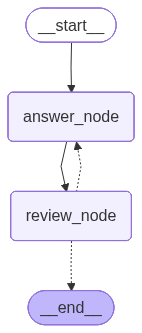

In [23]:
from IPython.display import Image, display
display(Image(graph.get_graph(xray=1).draw_mermaid_png()))

In [24]:
review_example = womens_reviews_df['Review Text'].iloc[0]
type(review_example)

str

In [25]:
graph.invoke(OverallState(review_text=review_example, sentiment="", reasoning="", agreement=False))

Processing first review. Generating sentiment analysis.
Reviewer agrees with the sentiment analysis or review count exceeded. Ending process.


{'review_text': 'Absolutely wonderful - silky and sexy and comfortable',
 'sentiment': 'good',
 'reasoning': "The review uses positive adjectives such as 'wonderful', 'silky', 'sexy', and 'comfortable', which all convey a strong sense of satisfaction and enjoyment. The overall tone is enthusiastic, indicating a very favorable opinion.",
 'agreement': True,
 'review_reasoning': "I agree with the sentiment of 'good' because the reasoning accurately identifies the use of positive adjectives that reflect satisfaction and enjoyment. The words 'wonderful', 'silky', 'sexy', and 'comfortable' indeed create an enthusiastic tone, supporting the conclusion that the review expresses a favorable opinion.",
 'review_count': 1}

In [26]:
graph.invoke({"review_text": review_example})

Processing first review. Generating sentiment analysis.
Reviewer agrees with the sentiment analysis or review count exceeded. Ending process.


{'review_text': 'Absolutely wonderful - silky and sexy and comfortable',
 'sentiment': 'good',
 'reasoning': "The review uses positive adjectives such as 'wonderful', 'silky', 'sexy', and 'comfortable', which all convey a strong sense of satisfaction and enjoyment. The overall tone is enthusiastic, indicating a very favorable opinion.",
 'agreement': True,
 'review_reasoning': "I agree with the sentiment of 'good' because the reasoning accurately identifies the use of positive adjectives that reflect satisfaction and enjoyment. The words 'wonderful', 'silky', 'sexy', and 'comfortable' indeed create an enthusiastic tone, supporting the conclusion that the review expresses a favorable opinion.",
 'review_count': 1}

In [28]:
sample_df = womens_reviews_df[['Review Text', 'Rating', 'Sentiment']].head(5)


In [29]:
sample_df

,Review Text,Rating,Sentiment
0,Absolutely wonderful - silky and sexy and comf...,4,good
1,Love this dress! it's sooo pretty. i happene...,5,good
2,I had such high hopes for this dress and reall...,3,neutral
3,"I love, love, love this jumpsuit. it's fun, fl...",5,good
4,This shirt is very flattering to all due to th...,5,good


In [30]:
inputs = [{"review_text": text} for text in sample_df['Review Text']]
results = graph.batch(inputs)

Processing first review. Generating sentiment analysis.
Processing first review. Generating sentiment analysis.
Processing first review. Generating sentiment analysis.
Processing first review. Generating sentiment analysis.
Processing first review. Generating sentiment analysis.
Reviewer agrees with the sentiment analysis or review count exceeded. Ending process.
Reviewer agrees with the sentiment analysis or review count exceeded. Ending process.
Reviewer agrees with the sentiment analysis or review count exceeded. Ending process.
Reviewer agrees with the sentiment analysis or review count exceeded. Ending process.
Reviewer agrees with the sentiment analysis or review count exceeded. Ending process.


In [31]:
results

[{'review_text': 'Absolutely wonderful - silky and sexy and comfortable',
  'sentiment': 'good',
  'reasoning': "The review uses positive adjectives such as 'wonderful', 'silky', 'sexy', and 'comfortable', which all convey a strong sense of satisfaction and enjoyment. The overall tone is enthusiastic, indicating a very favorable opinion.",
  'agreement': True,
  'review_reasoning': "I agree with the sentiment of 'good' because the reasoning accurately identifies the use of positive adjectives that reflect satisfaction and enjoyment. The words 'wonderful', 'silky', 'sexy', and 'comfortable' indeed create an enthusiastic tone, supporting the conclusion that the review expresses a favorable opinion.",
  'review_count': 1},
 {'review_text': 'Love this dress!  it\'s sooo pretty.  i happened to find it in a store, and i\'m glad i did bc i never would have ordered it online bc it\'s petite.  i bought a petite and am 5\'8".  i love the length on me- hits just a little below the knee.  would de

In [32]:
results_df = pd.DataFrame(results)
sample_final_df = pd.concat([sample_df, results_df], axis=1)
sample_final_df

,Review Text,Rating,Sentiment,review_text,sentiment,reasoning,agreement,review_reasoning,review_count
0,Absolutely wonderful - silky and sexy and comf...,4,good,Absolutely wonderful - silky and sexy and comf...,good,The review uses positive adjectives such as 'w...,True,I agree with the sentiment of 'good' because t...,1
1,Love this dress! it's sooo pretty. i happene...,5,good,Love this dress! it's sooo pretty. i happene...,good,The review expresses a strong positive sentime...,True,I agree with the sentiment of 'good' because t...,1
2,I had such high hopes for this dress and reall...,3,neutral,I had such high hopes for this dress and reall...,poor,The review expresses disappointment and frustr...,True,I agree with the sentiment of 'poor' because t...,1
3,"I love, love, love this jumpsuit. it's fun, fl...",5,good,"I love, love, love this jumpsuit. it's fun, fl...",good,The review expresses strong positive feelings ...,True,I agree with the sentiment of 'good' because t...,1
4,This shirt is very flattering to all due to th...,5,good,This shirt is very flattering to all due to th...,good,The review expresses positive feelings about t...,True,I agree with the sentiment of 'good' because t...,1


In [38]:
from sklearn.metrics import classification_report

print(classification_report(sample_final_df['Sentiment'], sample_final_df['sentiment']))

              precision    recall  f1-score   support

        good       1.00      1.00      1.00         4
     neutral       0.00      0.00      0.00         1
        poor       0.00      0.00      0.00         0

    accuracy                           0.80         5
   macro avg       0.33      0.33      0.33         5
weighted avg       0.80      0.80      0.80         5



/Users/adityanarvekar/agentic/agents/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/adityanarvekar/agentic/agents/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/adityanarvekar/agentic/agents/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modif